# Modelowanie – LightGBM vs XGBoost vs Random Forest + ensemble

**Wejście:** `data/processed/train_fe.parquet` (wynik `feature_engineering.ipynb`)

**Problem niezbalansowania** (8% klasy 1) adresujemy na kilku poziomach:
1. **Podziały stratyfikowane** – każdy fold i zbiór testowy ma ten sam odsetek defaultów.
2. **Metryki odporne na niezbalansowanie** – ROC AUC (główna), PR AUC (średnia precyzja), KS. Accuracy pomijamy (model „zawsze 0” ma 92%).
3. **Wagi klas** – eksperyment: bez wag vs √(neg/pos) vs pełne zrównoważenie (neg/pos). Wybrany wariant stosujemy we wszystkich modelach.
4. **Próg decyzyjny** – zamiast domyślnego 0,5 dobieramy próg maksymalizujący F1 na predykcjach OOF (bez zaglądania do testu).

**Schemat walidacji:**
- 20% danych odkładamy jako **holdout** – używany tylko raz, do końcowego porównania.
- Na pozostałych 80%: **5-fold stratified CV** → predykcje out-of-fold (OOF), liczba drzew z early stoppingu, wybór progu.
- Model końcowy trenowany na całych 80% z liczbą drzew = średnia z CV × 1,1 → ocena na holdoucie.
- **Ensemble LightGBM + XGBoost:** waga mieszania dobierana na OOF, ocena na tym samym holdoucie.

In [1]:
import json
import time
import warnings
from pathlib import Path
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import lightgbm as lgb
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             brier_score_loss, log_loss, confusion_matrix, f1_score, precision_score, recall_score)
from sklearn.calibration import calibration_curve

pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

# Kolory: modele = sloty kategoryczne 1–3; klasy 0/1 = niebieski/pomarańczowy (jak w EDA)
MODEL_COLORS = {'LightGBM': '#2a78d6', 'XGBoost': '#eb6834', 'RandomForest': '#1baf7a', 'Ensemble': '#e87ba4'}
BASE_MODELS = ['LightGBM', 'XGBoost', 'RandomForest']
C0, C1 = '#2a78d6', '#eb6834'
INK, MUTED, GRID = '#0b0b0b', '#898781', '#e1e0d9'
plt.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e', 'axes.titlecolor': INK,
    'axes.titleweight': 'bold', 'axes.titlesize': 11, 'axes.grid': True,
    'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'legend.frameon': False, 'font.size': 9,
})

SEED = 42
OUT = Path('data/processed')

## 1. Dane i podział

In [2]:
df = pd.read_parquet(OUT / 'train_fe.parquet')
meta = json.loads((OUT / 'feature_list.json').read_text(encoding='utf-8'))
FEATURES, CAT = meta['features'], meta['categorical']

X = df[FEATURES]
y = df['TARGET'].astype(int)

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
NEG_POS = (y_tr == 0).sum() / (y_tr == 1).sum()

pd.DataFrame({
    'wiersze': [len(y_tr), len(y_te)],
    'liczba 1': [y_tr.sum(), y_te.sum()],
    'odsetek 1': [y_tr.mean(), y_te.mean()],
}, index=['train (CV)', 'holdout'])

,wiersze,liczba 1,odsetek 1
train (CV),246008,19860,0.0807
holdout,61503,4965,0.0807


In [3]:
print(f'Cechy: {len(FEATURES)} (w tym kategoryczne: {len(CAT)})')
print(f'Stosunek neg/pos w train: {NEG_POS:.2f}  →  √ = {np.sqrt(NEG_POS):.2f}')

# Random Forest w sklearn nie obsługuje typu category → kody całkowite (NaN zostaje NaN; RF ≥ 1.4 obsługuje braki)
def to_numeric(X):
    X = X.copy()
    for c in CAT:
        X[c] = X[c].cat.codes.replace(-1, np.nan).astype('float32')
    return X

X_tr_num, X_te_num = to_numeric(X_tr), to_numeric(X_te)

Cechy: 120 (w tym kategoryczne: 11)
Stosunek neg/pos w train: 11.39  →  √ = 3.37


## 2. Narzędzia: metryki i CV

In [4]:
def ks_stat(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return np.max(tpr - fpr)

def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    i = np.nanargmax(f1[:-1])
    return thr[i], f1[i]

def capture_at(y, p, frac=0.1):
    """Jaki odsetek wszystkich defaultów trafia do top `frac` najwyżej ocenionych wniosków."""
    k = int(len(p) * frac)
    idx = np.argsort(-p)[:k]
    return y.values[idx].sum() / y.sum()

def evaluate(y, p, thr):
    yhat = (p >= thr).astype(int)
    return {
        'ROC AUC': roc_auc_score(y, p),
        'PR AUC': average_precision_score(y, p),
        'Gini': 2 * roc_auc_score(y, p) - 1,
        'KS': ks_stat(y, p),
        'F1': f1_score(y, yhat),
        'Precision': precision_score(y, yhat),
        'Recall': recall_score(y, yhat),
        'Capture@10%': capture_at(y, p, 0.1),
        'Brier': brier_score_loss(y, p),
        'próg': thr,
    }

def run_cv(fit_predict, X, y, n_splits=5):
    """fit_predict(X_a, y_a, X_b, y_b) -> (proba_b, best_iter). Zwraca OOF, AUC per fold, liczby drzew, czas."""
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    oof, aucs, iters = np.zeros(len(y)), [], []
    t0 = time.time()
    for tr, va in skf.split(X, y):
        p, it = fit_predict(X.iloc[tr], y.iloc[tr], X.iloc[va], y.iloc[va])
        oof[va] = p
        aucs.append(roc_auc_score(y.iloc[va], p))
        iters.append(it)
    return {'oof': oof, 'fold_auc': np.array(aucs), 'iters': iters, 'time': time.time() - t0}

## 3. Niezbalansowanie klas – eksperyment z wagami (LightGBM)

Trzy warianty `scale_pos_weight`: brak wag (1), √(neg/pos) i pełne zrównoważenie (neg/pos).
Porównanie na 5-fold CV zbioru treningowego.

In [5]:
LGB_BASE = dict(
    objective='binary', metric='auc',   # tylko AUC – inaczej early stopping reaguje też na logloss (psuje się przy wagach)
    learning_rate=0.05, n_estimators=5000, num_leaves=31, min_child_samples=100, subsample=0.8, subsample_freq=1,
    colsample_bytree=0.4, reg_lambda=2.0, n_jobs=-1, random_state=SEED, verbose=-1,
)

def lgb_fp(params):
    def fp(Xa, ya, Xb, yb):
        m = lgb.LGBMClassifier(**params)
        m.fit(Xa, ya, eval_set=[(Xb, yb)], eval_metric='auc',
              callbacks=[lgb.early_stopping(100, verbose=False)])
        return m.predict_proba(Xb)[:, 1], m.best_iteration_
    return fp

weight_variants = {'brak wag (1)': 1.0, f'√(neg/pos) = {np.sqrt(NEG_POS):.1f}': np.sqrt(NEG_POS),
                   f'neg/pos = {NEG_POS:.1f}': NEG_POS}
weight_res = {}
for name, spw in weight_variants.items():
    r = run_cv(lgb_fp({**LGB_BASE, 'scale_pos_weight': spw}), X_tr, y_tr)
    oof = r['oof']
    thr, _ = best_f1_threshold(y_tr, oof)
    weight_res[name] = {
        'scale_pos_weight': spw,
        'ROC AUC': roc_auc_score(y_tr, oof),
        'PR AUC': average_precision_score(y_tr, oof),
        'Recall @0.5': recall_score(y_tr, oof >= 0.5),
        'Precision @0.5': precision_score(y_tr, oof >= 0.5),
        'F1 @0.5': f1_score(y_tr, oof >= 0.5),
        'F1 @ najlepszy próg': f1_score(y_tr, oof >= thr),
        'najlepszy próg': thr,
        'średnia predykcja': oof.mean(),
        'Brier': brier_score_loss(y_tr, oof),
        'drzewa (śr.)': np.mean(r['iters']),
        '_oof': oof,
    }
    print(f"{name:22s} AUC {weight_res[name]['ROC AUC']:.4f}  ({r['time']:.0f}s)")

weight_tbl = pd.DataFrame(weight_res).T.drop(columns='_oof').astype(float)
weight_tbl

brak wag (1)           AUC 0.7660  (55s)


√(neg/pos) = 3.4       AUC 0.7659  (60s)


neg/pos = 11.4         AUC 0.7643  (51s)


,scale_pos_weight,ROC AUC,PR AUC,Recall @0.5,Precision @0.5,F1 @0.5,F1 @ najlepszy próg,najlepszy próg,średnia predykcja,Brier,drzewa (śr.)
brak wag (1),1.0000,0.7660,0.2483,0.0229,0.5328,0.0439,0.3110,0.1593,0.0802,0.0675,375.0000
√(neg/pos) = 3.4,3.3745,0.7659,0.2492,0.2357,0.3241,0.2729,0.3115,0.3567,0.1942,0.0860,374.4000
neg/pos = 11.4,11.3871,0.7643,0.2478,0.6615,0.1769,0.2792,0.3098,0.6653,0.3810,0.1800,331.8000


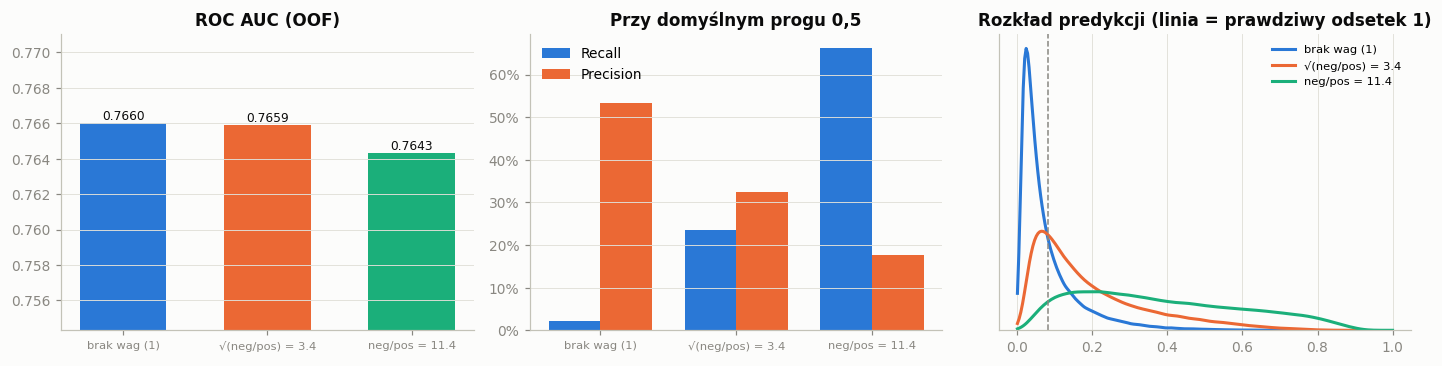

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
names = list(weight_res)
w_colors = ['#2a78d6', '#eb6834', '#1baf7a']

ax = axes[0]
vals = [weight_res[n]['ROC AUC'] for n in names]
ax.bar(range(3), vals, color=w_colors, width=0.6)
for i, v in enumerate(vals):
    ax.text(i, v, f'{v:.4f}', ha='center', va='bottom', fontsize=8, color=INK)
ax.set_ylim(min(vals) - 0.01, max(vals) + 0.005)
ax.set_xticks(range(3)); ax.set_xticklabels(names, fontsize=7.5)
ax.set_title('ROC AUC (OOF)'); ax.grid(axis='x', visible=False)

ax = axes[1]
x = np.arange(3); w = 0.38
rec = [weight_res[n]['Recall @0.5'] for n in names]
pre = [weight_res[n]['Precision @0.5'] for n in names]
ax.bar(x - w/2, rec, w, color=C0, label='Recall')
ax.bar(x + w/2, pre, w, color=C1, label='Precision')
ax.set_xticks(x); ax.set_xticklabels(names, fontsize=7.5)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_title('Przy domyślnym progu 0,5'); ax.legend(); ax.grid(axis='x', visible=False)

ax = axes[2]
for n, c in zip(names, w_colors):
    sns.kdeplot(weight_res[n]['_oof'], ax=ax, color=c, lw=2, label=n, clip=(0, 1))
ax.axvline(y_tr.mean(), color=MUTED, ls='--', lw=1)
ax.set_title('Rozkład predykcji (linia = prawdziwy odsetek 1)')
ax.set_yticks([]); ax.set_ylabel(''); ax.legend(fontsize=7.5)
plt.tight_layout(); plt.show()

In [7]:
# Wybór wariantu: najwyższe ROC AUC. Ten sam wariant stosujemy w XGBoost i RF.
BEST_W = max(weight_res, key=lambda n: weight_res[n]['ROC AUC'])
SPW = weight_res[BEST_W]['scale_pos_weight']
RF_CLASS_WEIGHT = None if SPW == 1.0 else {0: 1.0, 1: float(SPW)}
print(f'Wybrany wariant: {BEST_W}  →  scale_pos_weight = {SPW:.2f}')

Wybrany wariant: brak wag (1)  →  scale_pos_weight = 1.00


## 4. Trening trzech modeli (5-fold CV)

Hiperparametry są rozsądnymi wartościami startowymi (bez tuningu) – porównujemy algorytmy w równych warunkach:
ten sam podział, te same cechy, te same wagi klas.
- **LightGBM:** natywne kategorie, early stopping po AUC.
- **XGBoost:** `tree_method='hist'`, natywne kategorie (`enable_categorical`), early stopping po AUC.
- **Random Forest:** 400 drzew, kategorie jako kody, obsługa NaN wbudowana w sklearn ≥ 1.4.

In [8]:
LGB_PARAMS = {**LGB_BASE, 'scale_pos_weight': SPW}

XGB_PARAMS = dict(
    n_estimators=5000, learning_rate=0.05, max_depth=6, min_child_weight=10,
    subsample=0.8, colsample_bytree=0.4, reg_lambda=2.0, tree_method='hist',
    enable_categorical=True, max_cat_to_onehot=1, eval_metric='auc',
    scale_pos_weight=SPW, n_jobs=-1, random_state=SEED,
)

RF_PARAMS = dict(
    n_estimators=400, min_samples_leaf=20, max_features='sqrt', max_samples=0.5,
    class_weight=RF_CLASS_WEIGHT, n_jobs=-1, random_state=SEED,
)

def xgb_fp(Xa, ya, Xb, yb):
    m = xgb.XGBClassifier(**XGB_PARAMS, early_stopping_rounds=100)
    m.fit(Xa, ya, eval_set=[(Xb, yb)], verbose=False)
    return m.predict_proba(Xb)[:, 1], m.best_iteration + 1

def rf_fp(Xa, ya, Xb, yb):
    m = RandomForestClassifier(**RF_PARAMS)
    m.fit(Xa, ya)
    return m.predict_proba(Xb)[:, 1], RF_PARAMS['n_estimators']

cv_res = {}
cv_res['LightGBM'] = run_cv(lgb_fp(LGB_PARAMS), X_tr, y_tr)
cv_res['XGBoost'] = run_cv(xgb_fp, X_tr, y_tr)
cv_res['RandomForest'] = run_cv(rf_fp, X_tr_num, y_tr)

cv_tbl = pd.DataFrame({
    m: {'OOF AUC': roc_auc_score(y_tr, r['oof']), 'AUC fold – średnia': r['fold_auc'].mean(),
        'AUC fold – std': r['fold_auc'].std(), 'PR AUC (OOF)': average_precision_score(y_tr, r['oof']),
        'drzewa (śr.)': np.mean(r['iters']), 'czas CV [s]': r['time']}
    for m, r in cv_res.items()}).T
cv_tbl

,OOF AUC,AUC fold – średnia,AUC fold – std,PR AUC (OOF),drzewa (śr.),czas CV [s]
LightGBM,0.7660,0.7660,0.0013,0.2483,375.0000,49.2346
XGBoost,0.7648,0.7648,0.0017,0.2467,367.8000,161.9455
RandomForest,0.7474,0.7475,0.0029,0.2291,400.0000,212.4862


## 5. Modele końcowe i ocena na holdoucie

Próg decyzyjny dla każdego modelu wybieramy na **OOF** (maksymalizacja F1) i dopiero potem stosujemy na holdoucie.

In [9]:
final_models, pred_te, thresholds, fit_time = {}, {}, {}, {}

for name in cv_res:
    thresholds[name], _ = best_f1_threshold(y_tr, cv_res[name]['oof'])

n_lgb = int(np.mean(cv_res['LightGBM']['iters']) * 1.1)
n_xgb = int(np.mean(cv_res['XGBoost']['iters']) * 1.1)

t0 = time.time()
final_models['LightGBM'] = lgb.LGBMClassifier(**{**LGB_PARAMS, 'n_estimators': n_lgb}).fit(X_tr, y_tr)
fit_time['LightGBM'] = time.time() - t0

t0 = time.time()
final_models['XGBoost'] = xgb.XGBClassifier(**{**XGB_PARAMS, 'n_estimators': n_xgb}).fit(X_tr, y_tr, verbose=False)
fit_time['XGBoost'] = time.time() - t0

t0 = time.time()
final_models['RandomForest'] = RandomForestClassifier(**RF_PARAMS).fit(X_tr_num, y_tr)
fit_time['RandomForest'] = time.time() - t0

pred_te['LightGBM'] = final_models['LightGBM'].predict_proba(X_te)[:, 1]
pred_te['XGBoost'] = final_models['XGBoost'].predict_proba(X_te)[:, 1]
pred_te['RandomForest'] = final_models['RandomForest'].predict_proba(X_te_num)[:, 1]

results = pd.DataFrame({m: evaluate(y_te, pred_te[m], thresholds[m]) for m in pred_te}).T
results['czas treningu [s]'] = pd.Series(fit_time)
results.sort_values('ROC AUC', ascending=False)

,ROC AUC,PR AUC,Gini,KS,F1,Precision,Recall,Capture@10%,Brier,próg,czas treningu [s]
LightGBM,0.7709,0.2630,0.5418,0.4049,0.3197,0.2597,0.4159,0.3557,0.0669,0.1593,11.2070
XGBoost,0.7707,0.2605,0.5413,0.4003,0.3186,0.2412,0.4691,0.3573,0.0670,0.1413,16.1252
RandomForest,0.7501,0.2378,0.5001,0.3687,0.3035,0.2333,0.4342,0.3360,0.0682,0.1452,63.0695


## 5b. Ensemble LightGBM + XGBoost

Łączymy dwa najlepsze modele. Random Forest pomijamy: jest o ~0,02 AUC słabszy, więc dołożenie go raczej rozcieńczy sygnał.

Porównujemy trzy sposoby łączenia, wszystkie na **OOF** (holdout nadal nietknięty):
- **średnia prawdopodobieństw 50/50**,
- **średnia rang 50/50** – odporna na różną skalę predykcji, ale wynik przestaje być prawdopodobieństwem,
- **średnia ważona** `w · LightGBM + (1 − w) · XGBoost` z wagą `w` dobraną na siatce 0…1 (krok 0,05).

Dobieramy tylko jeden parametr (`w`) na ~246 tys. wierszy OOF, więc ryzyko przeuczenia jest pomijalne.
Jako ensemble końcowy bierzemy **średnią ważoną prawdopodobieństw** – zachowuje kalibrację, czyli interpretację jako PD.

In [10]:
from scipy.stats import rankdata, pearsonr, spearmanr

def rank01(p):
    return (rankdata(p) - 1) / (len(p) - 1)

oof_l, oof_x = cv_res['LightGBM']['oof'], cv_res['XGBoost']['oof']
print(f'Korelacja predykcji OOF LightGBM vs XGBoost:  Pearson {pearsonr(oof_l, oof_x)[0]:.4f},  '
      f'Spearman {spearmanr(oof_l, oof_x)[0]:.4f}')

ENS_WEIGHTS = np.round(np.arange(0, 1.0001, 0.05), 2)
auc_w_oof = np.array([roc_auc_score(y_tr, w * oof_l + (1 - w) * oof_x) for w in ENS_WEIGHTS])
auc_w_te = np.array([roc_auc_score(y_te, w * pred_te['LightGBM'] + (1 - w) * pred_te['XGBoost'])
                     for w in ENS_WEIGHTS])
W_BEST = float(ENS_WEIGHTS[auc_w_oof.argmax()])
print(f'Najlepsza waga LightGBM na OOF: w = {W_BEST:.2f}  (XGBoost: {1 - W_BEST:.2f})')

def blends(pl, px):
    return {
        'LightGBM': pl,
        'XGBoost': px,
        'średnia 50/50': 0.5 * pl + 0.5 * px,
        'średnia rang 50/50': 0.5 * rank01(pl) + 0.5 * rank01(px),
        f'ważona (w={W_BEST:.2f})': W_BEST * pl + (1 - W_BEST) * px,
    }

def blend_table(y, b):
    return pd.DataFrame({k: {'ROC AUC': roc_auc_score(y, p), 'PR AUC': average_precision_score(y, p),
                             'Brier': brier_score_loss(y, p) if 'rang' not in k else np.nan}
                         for k, p in b.items()}).T

blend_tbl = pd.concat({'OOF': blend_table(y_tr, blends(oof_l, oof_x)),
                       'holdout': blend_table(y_te, blends(pred_te['LightGBM'], pred_te['XGBoost']))}, axis=1)
blend_tbl

Korelacja predykcji OOF LightGBM vs XGBoost:  Pearson 0.9709,  Spearman 0.9718


Najlepsza waga LightGBM na OOF: w = 0.60  (XGBoost: 0.40)


OOF               holdout              
                   ROC AUC PR AUC  Brier ROC AUC PR AUC  Brier
LightGBM            0.7660 0.2483 0.0675  0.7709 0.2630 0.0669
XGBoost             0.7648 0.2467 0.0676  0.7707 0.2605 0.0670
średnia 50/50       0.7669 0.2496 0.0674  0.7722 0.2639 0.0669
średnia rang 50/50  0.7668 0.2497    NaN  0.7721 0.2636    NaN
ważona (w=0.60)     0.7669 0.2497 0.0674  0.7721 0.2640 0.0669

In [11]:
# Ensemble końcowy = średnia ważona prawdopodobieństw. Próg max-F1 – jak dla pozostałych modeli – z OOF.
ENS = 'Ensemble'
oof_ens = W_BEST * oof_l + (1 - W_BEST) * oof_x
pred_te[ENS] = W_BEST * pred_te['LightGBM'] + (1 - W_BEST) * pred_te['XGBoost']
thresholds[ENS], _ = best_f1_threshold(y_tr, oof_ens)

# AUC w foldach – te same foldy co w run_cv (ten sam seed), więc porównanie jest parami
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
fold_idx = [va for _, va in skf.split(X_tr, y_tr)]
cv_res[ENS] = {'oof': oof_ens, 'fold_auc': np.array([roc_auc_score(y_tr.iloc[va], oof_ens[va]) for va in fold_idx]),
               'iters': None, 'time': cv_res['LightGBM']['time'] + cv_res['XGBoost']['time']}
fit_time[ENS] = fit_time['LightGBM'] + fit_time['XGBoost']

gain = cv_res[ENS]['fold_auc'] - np.maximum(cv_res['LightGBM']['fold_auc'], cv_res['XGBoost']['fold_auc'])
print('Zysk AUC ensemble vs lepszy z dwóch modeli w każdym foldzie:', np.round(gain, 4),
      f'→ poprawa w {(gain > 0).sum()}/5 foldach')

results = pd.DataFrame({m: evaluate(y_te, pred_te[m], thresholds[m]) for m in pred_te}).T
results['czas treningu [s]'] = pd.Series(fit_time)
results.sort_values('ROC AUC', ascending=False)

Zysk AUC ensemble vs lepszy z dwóch modeli w każdym foldzie: [0.0011 0.0007 0.0012 0.0006 0.001 ] → poprawa w 5/5 foldach


,ROC AUC,PR AUC,Gini,KS,F1,Precision,Recall,Capture@10%,Brier,próg,czas treningu [s]
Ensemble,0.7721,0.2640,0.5442,0.4049,0.3212,0.2534,0.4383,0.3569,0.0669,0.1520,27.3321
LightGBM,0.7709,0.2630,0.5418,0.4049,0.3197,0.2597,0.4159,0.3557,0.0669,0.1593,11.2070
XGBoost,0.7707,0.2605,0.5413,0.4003,0.3186,0.2412,0.4691,0.3573,0.0670,0.1413,16.1252
RandomForest,0.7501,0.2378,0.5001,0.3687,0.3035,0.2333,0.4342,0.3360,0.0682,0.1452,63.0695


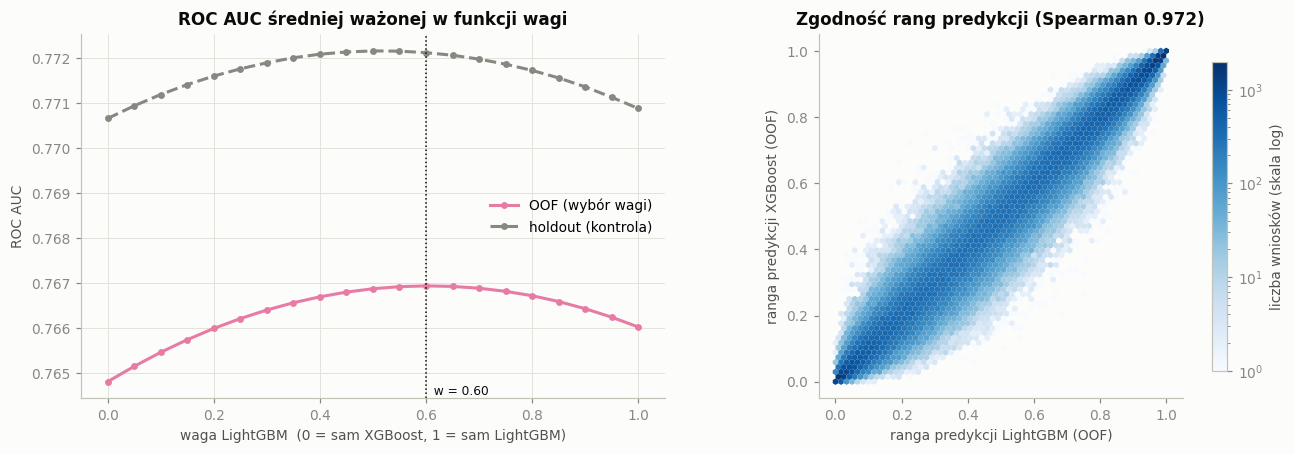

In [12]:
# Ensemble – wpływ wagi i zgodność predykcji
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.plot(ENS_WEIGHTS, auc_w_oof, color=MODEL_COLORS[ENS], lw=2, marker='o', ms=3.5, label='OOF (wybór wagi)')
ax.plot(ENS_WEIGHTS, auc_w_te, color=MUTED, lw=2, ls='--', marker='o', ms=3.5, label='holdout (kontrola)')
ax.axvline(W_BEST, color=INK, lw=1, ls=':')
ax.text(W_BEST, ax.get_ylim()[0], f'  w = {W_BEST:.2f}', va='bottom', fontsize=8, color=INK)
ax.set_xlabel('waga LightGBM  (0 = sam XGBoost, 1 = sam LightGBM)'); ax.set_ylabel('ROC AUC')
ax.set_title('ROC AUC średniej ważonej w funkcji wagi'); ax.legend(loc='center right')

ax = axes[1]
hb = ax.hexbin(rank01(oof_l), rank01(oof_x), gridsize=60, bins='log', cmap='Blues', mincnt=1, linewidths=0)
ax.set_xlabel('ranga predykcji LightGBM (OOF)'); ax.set_ylabel('ranga predykcji XGBoost (OOF)')
ax.set_title(f'Zgodność rang predykcji (Spearman {spearmanr(oof_l, oof_x)[0]:.3f})'); ax.grid(False)
ax.set_aspect('equal')
fig.colorbar(hb, ax=ax, label='liczba wniosków (skala log)', shrink=0.85)
plt.tight_layout(); plt.show()

In [13]:
# Przedziały ufności (bootstrap, 500 prób) dla AUC na holdoucie i różnicy względem najlepszego modelu
rng = np.random.default_rng(SEED)
yv = y_te.values
boot = {m: [] for m in pred_te}
for _ in range(500):
    idx = rng.integers(0, len(yv), len(yv))
    for m in pred_te:
        boot[m].append(roc_auc_score(yv[idx], pred_te[m][idx]))
boot = pd.DataFrame(boot)
best = results['ROC AUC'].idxmax()

ci = pd.DataFrame({
    'AUC': results['ROC AUC'],
    'CI 2.5%': boot.quantile(0.025),
    'CI 97.5%': boot.quantile(0.975),
    f'różnica vs {best}': boot.sub(boot[best], axis=0).mean(),
    'CI różnicy 2.5%': boot.sub(boot[best], axis=0).quantile(0.025),
    'CI różnicy 97.5%': boot.sub(boot[best], axis=0).quantile(0.975),
}).sort_values('AUC', ascending=False)
ci

,AUC,CI 2.5%,CI 97.5%,różnica vs Ensemble,CI różnicy 2.5%,CI różnicy 97.5%
Ensemble,0.7721,0.7655,0.7787,0.0000,0.0000,0.0000
LightGBM,0.7709,0.7644,0.7775,-0.0012,-0.0019,-0.0006
XGBoost,0.7707,0.7641,0.7771,-0.0015,-0.0024,-0.0005
RandomForest,0.7501,0.7433,0.7574,-0.0221,-0.0252,-0.0192


## 6. Wykresy porównawcze

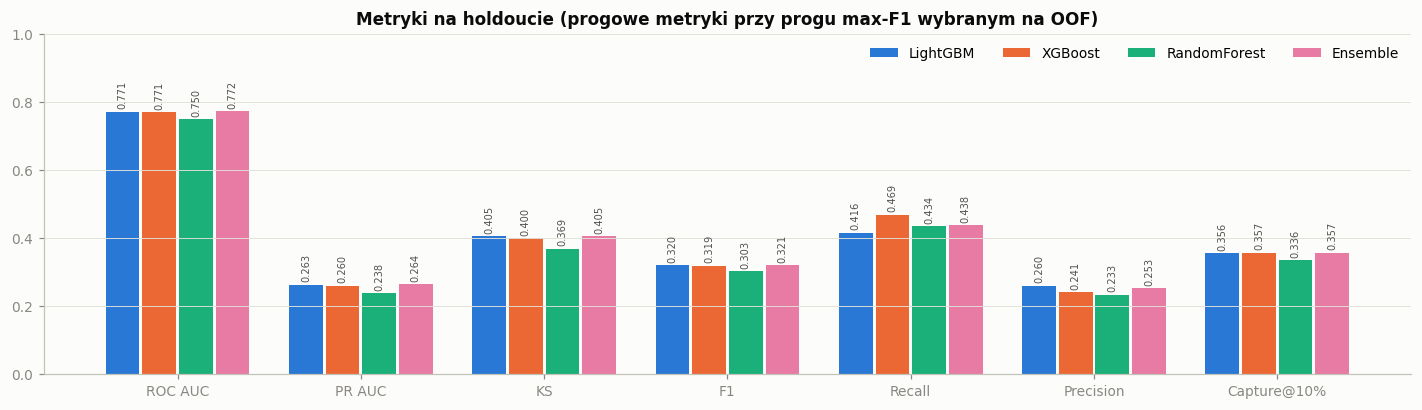

In [14]:
# 6a. Zestawienie metryk
metric_cols = ['ROC AUC', 'PR AUC', 'KS', 'F1', 'Recall', 'Precision', 'Capture@10%']
models = list(pred_te)
fig, ax = plt.subplots(figsize=(13, 3.8))
x = np.arange(len(metric_cols)); w = 0.8 / len(models)
for i, m in enumerate(models):
    vals = results.loc[m, metric_cols].values.astype(float)
    xs = x + (i - (len(models) - 1) / 2) * w
    bars = ax.bar(xs, vals, w * 0.92, color=MODEL_COLORS[m], label=m)
    for xb, v in zip(xs, vals):
        ax.text(xb, v + 0.008, f'{v:.3f}', ha='center', va='bottom', fontsize=6.5, color='#52514e', rotation=90)
ax.set_xticks(x); ax.set_xticklabels(metric_cols)
ax.set_ylim(0, 1.0); ax.set_title('Metryki na holdoucie (progowe metryki przy progu max-F1 wybranym na OOF)')
ax.legend(ncol=len(models), loc='upper right'); ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

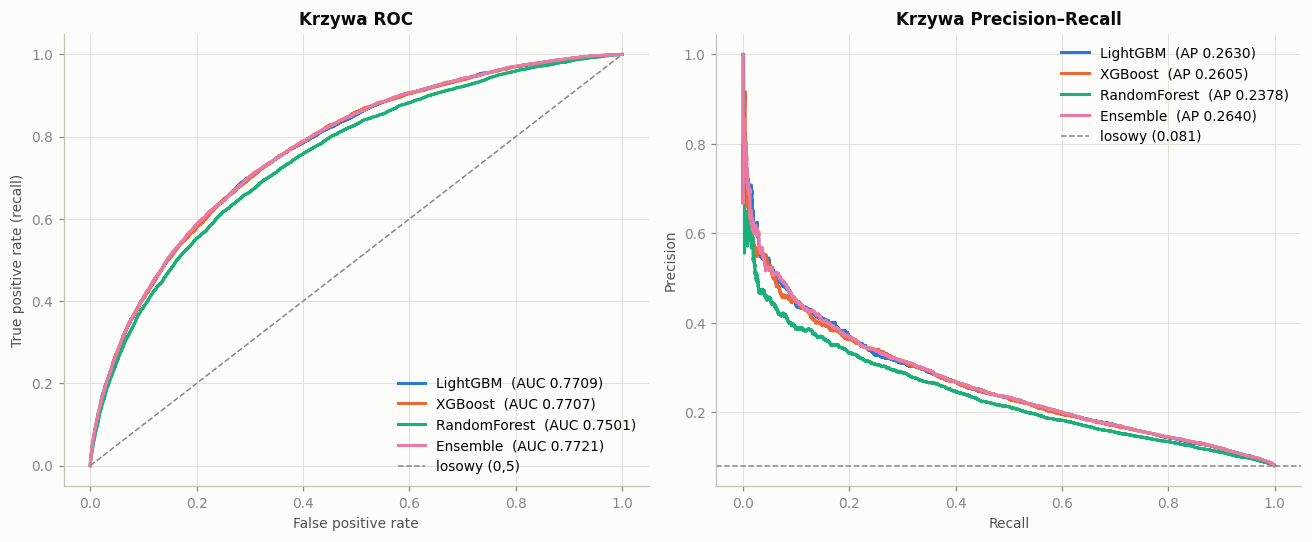

In [15]:
# 6b. Krzywe ROC i Precision–Recall
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ax = axes[0]
for m in models:
    fpr, tpr, _ = roc_curve(y_te, pred_te[m])
    ax.plot(fpr, tpr, color=MODEL_COLORS[m], lw=2, label=f"{m}  (AUC {results.loc[m, 'ROC AUC']:.4f})")
ax.plot([0, 1], [0, 1], color=MUTED, ls='--', lw=1, label='losowy (0,5)')
ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate (recall)')
ax.set_title('Krzywa ROC'); ax.legend(loc='lower right')

ax = axes[1]
for m in models:
    prec, rec, _ = precision_recall_curve(y_te, pred_te[m])
    ax.plot(rec, prec, color=MODEL_COLORS[m], lw=2, label=f"{m}  (AP {results.loc[m, 'PR AUC']:.4f})")
ax.axhline(y_te.mean(), color=MUTED, ls='--', lw=1, label=f'losowy ({y_te.mean():.3f})')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
ax.set_title('Krzywa Precision–Recall'); ax.legend(loc='upper right')
plt.tight_layout(); plt.show()

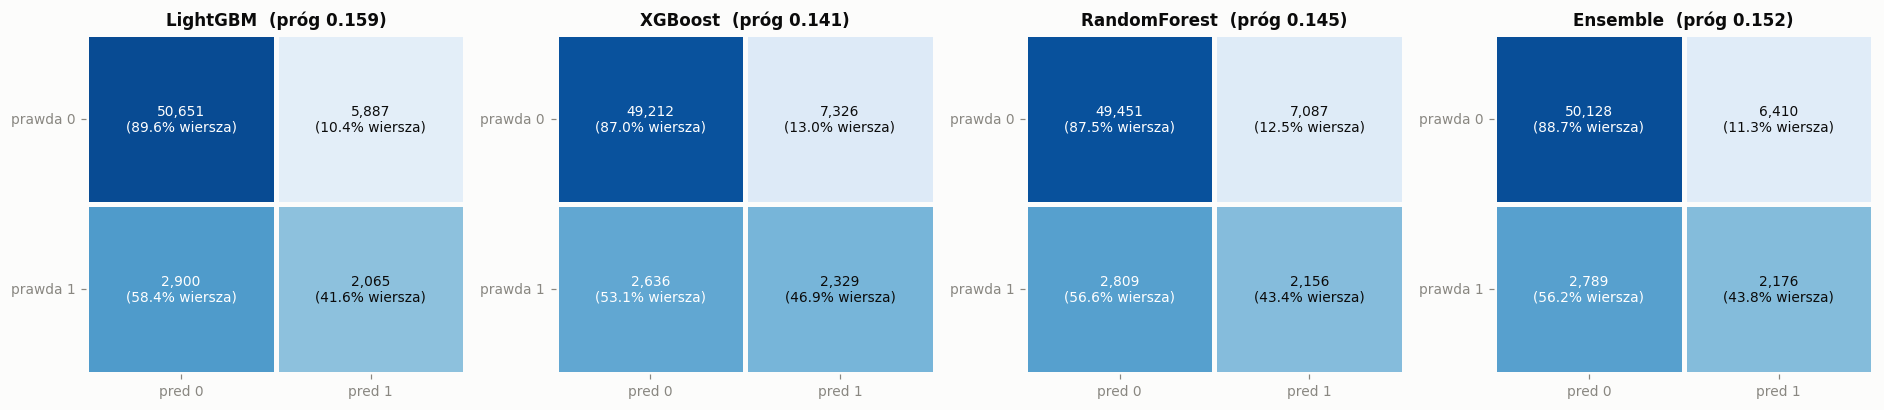

In [16]:
# 6c. Macierze pomyłek przy progu max-F1
fig, axes = plt.subplots(1, len(models), figsize=(4.3 * len(models), 3.8))
for ax, m in zip(axes, models):
    cm = confusion_matrix(y_te, pred_te[m] >= thresholds[m])
    share = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(share, annot=False, cmap='Blues', vmin=0, vmax=1, cbar=False, ax=ax,
                linewidths=2, linecolor='#fcfcfb')
    for i in range(2):
        for j in range(2):
            ax.text(j + 0.5, i + 0.5, f'{cm[i, j]:,}\n({share[i, j]:.1%} wiersza)', ha='center', va='center',
                    fontsize=9, color='white' if share[i, j] > 0.5 else INK)
    ax.grid(False)
    ax.set_xticklabels(['pred 0', 'pred 1']); ax.set_yticklabels(['prawda 0', 'prawda 1'], rotation=0)
    ax.set_title(f'{m}  (próg {thresholds[m]:.3f})')
plt.tight_layout(); plt.show()

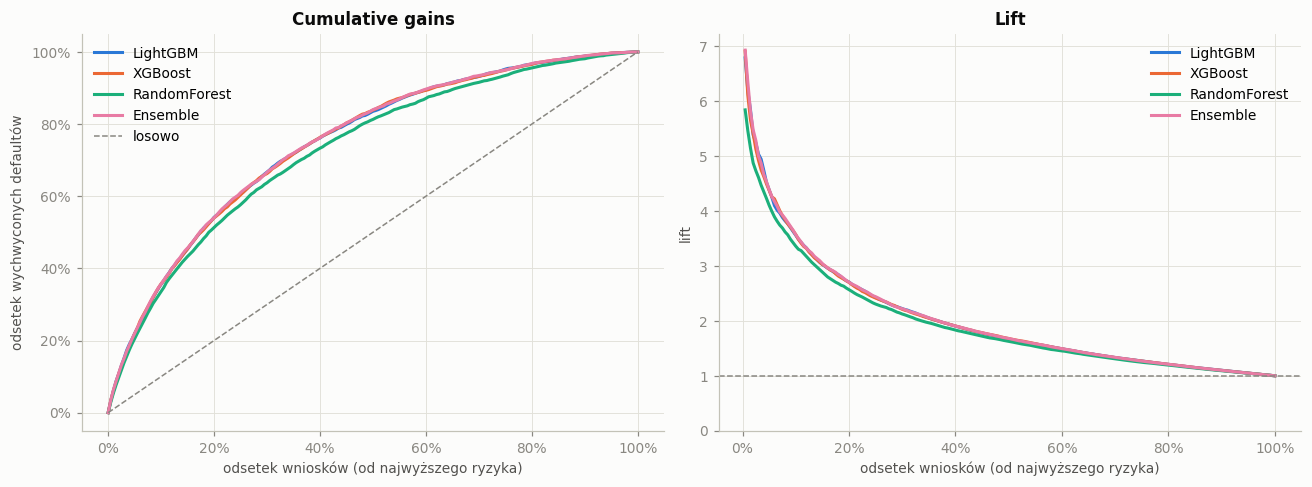

In [17]:
# 6d. Cumulative gains – ile defaultów łapiemy, odrzucając top X% najbardziej ryzykownych wniosków
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
frac = np.linspace(0, 1, 201)
for m in models:
    order = np.argsort(-pred_te[m])
    cum = np.concatenate([[0], np.cumsum(y_te.values[order])]) / y_te.sum()
    gains = np.interp(frac, np.linspace(0, 1, len(cum)), cum)
    axes[0].plot(frac, gains, color=MODEL_COLORS[m], lw=2, label=m)
    lift = np.divide(gains[1:], frac[1:])
    axes[1].plot(frac[1:], lift, color=MODEL_COLORS[m], lw=2, label=m)
axes[0].plot([0, 1], [0, 1], color=MUTED, ls='--', lw=1, label='losowo')
axes[0].set_xlabel('odsetek wniosków (od najwyższego ryzyka)'); axes[0].set_ylabel('odsetek wychwyconych defaultów')
axes[0].set_title('Cumulative gains')
axes[1].axhline(1, color=MUTED, ls='--', lw=1)
axes[1].set_xlabel('odsetek wniosków (od najwyższego ryzyka)'); axes[1].set_ylabel('lift')
axes[1].set_title('Lift'); axes[1].set_ylim(0, None)
for ax in axes:
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.legend()
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
plt.tight_layout(); plt.show()

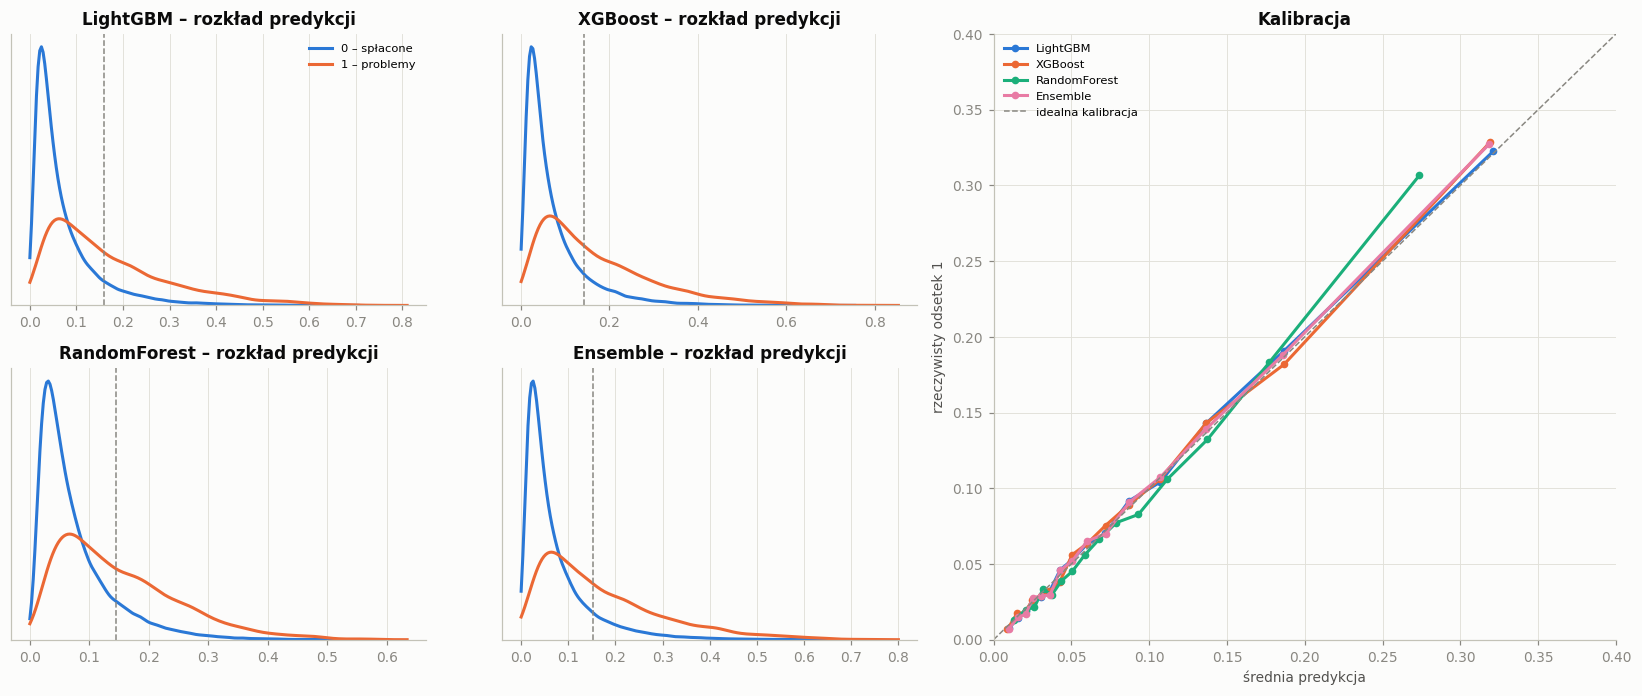

In [18]:
# 6e. Rozkład predykcji wg klasy i kalibracja
fig = plt.figure(figsize=(15, 6.4))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 1.5])
dist_axes = [fig.add_subplot(gs[r, c]) for r in range(2) for c in range(2)]
for ax, m in zip(dist_axes, models):
    p = pred_te[m]
    sns.kdeplot(p[y_te.values == 0], ax=ax, color=C0, lw=2, label='0 – spłacone', clip=(0, 1))
    sns.kdeplot(p[y_te.values == 1], ax=ax, color=C1, lw=2, label='1 – problemy', clip=(0, 1))
    ax.axvline(thresholds[m], color=MUTED, ls='--', lw=1)
    ax.set_title(f'{m} – rozkład predykcji'); ax.set_yticks([]); ax.set_ylabel(''); ax.set_xlabel('')
dist_axes[0].legend(fontsize=7.5)

ax = fig.add_subplot(gs[:, 2])
for m in models:
    pt, pp = calibration_curve(y_te, pred_te[m], n_bins=15, strategy='quantile')
    ax.plot(pp, pt, color=MODEL_COLORS[m], lw=2, marker='o', ms=4, label=m)
lim = 0.4
ax.plot([0, lim], [0, lim], color=MUTED, ls='--', lw=1, label='idealna kalibracja')
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel('średnia predykcja'); ax.set_ylabel('rzeczywisty odsetek 1')
ax.set_title('Kalibracja'); ax.legend(fontsize=7.5)
plt.tight_layout(); plt.show()

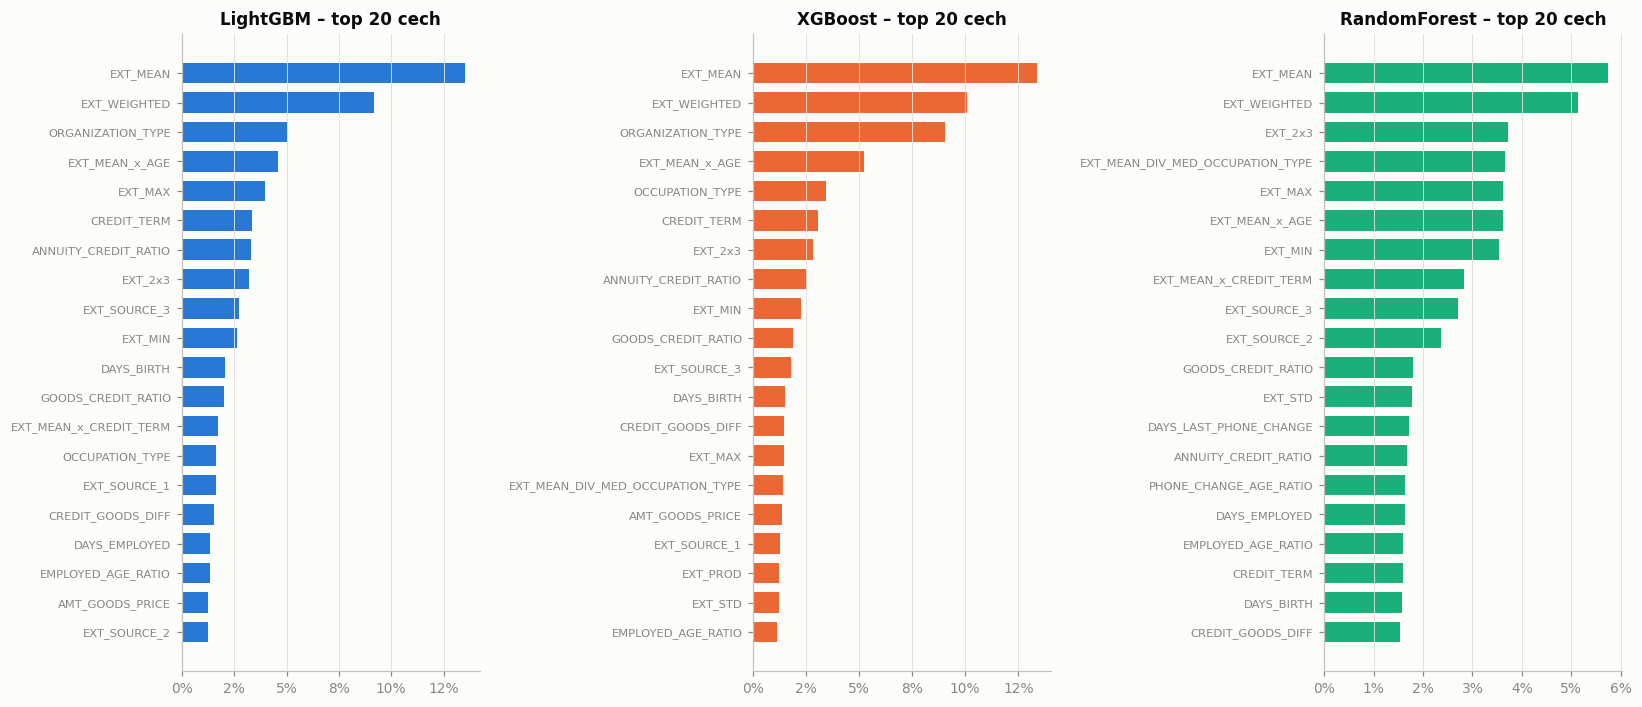

Korelacja Spearmana rankingów ważności cech:
              LightGBM  XGBoost  RandomForest
LightGBM        1.0000   0.9800        0.9300
XGBoost         0.9800   1.0000        0.9100
RandomForest    0.9300   0.9100        1.0000


In [19]:
# 6f. Ważność cech – top 20 dla każdego modelu (znormalizowana do 100%)
imp = pd.DataFrame({
    'LightGBM': pd.Series(final_models['LightGBM'].booster_.feature_importance('gain'), index=FEATURES),
    'XGBoost': pd.Series(final_models['XGBoost'].get_booster().get_score(importance_type='total_gain')).reindex(FEATURES).fillna(0),
    'RandomForest': pd.Series(final_models['RandomForest'].feature_importances_, index=FEATURES),
})
imp = imp / imp.sum()

# (ensemble nie ma własnej ważności – to średnia dwóch modeli)
fig, axes = plt.subplots(1, 3, figsize=(15, 6.5))
for ax, m in zip(axes, BASE_MODELS):
    t = imp[m].sort_values(ascending=False).head(20)[::-1]
    ax.barh(t.index, t.values, color=MODEL_COLORS[m], height=0.7)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
    ax.set_title(f'{m} – top 20 cech'); ax.grid(axis='y', visible=False)
    ax.tick_params(axis='y', labelsize=7.5)
plt.tight_layout(); plt.show()

# Zgodność rankingów ważności między modelami
print('Korelacja Spearmana rankingów ważności cech:')
print(imp.corr(method='spearman').round(2).to_string())

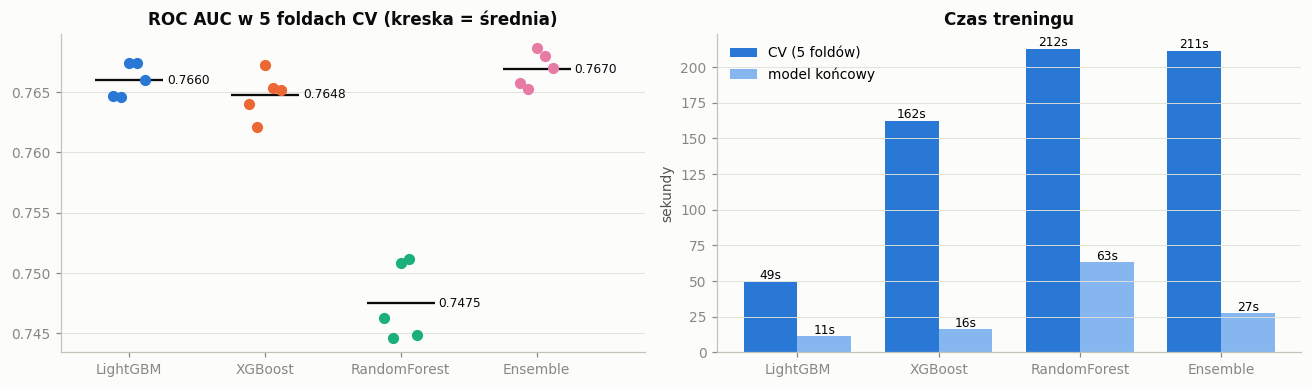

In [20]:
# 6g. Stabilność w CV i czas
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
ax = axes[0]
for i, m in enumerate(models):
    a = cv_res[m]['fold_auc']
    ax.scatter(np.full(len(a), i) + np.linspace(-0.12, 0.12, len(a)), a, color=MODEL_COLORS[m], s=40, zorder=3)
    ax.hlines(a.mean(), i - 0.25, i + 0.25, color=INK, lw=1.5)
    ax.text(i + 0.28, a.mean(), f'{a.mean():.4f}', va='center', fontsize=8, color=INK)
ax.set_xticks(range(len(models))); ax.set_xticklabels(models); ax.set_xlim(-0.5, len(models) - 0.2)
ax.set_title('ROC AUC w 5 foldach CV (kreska = średnia)'); ax.grid(axis='x', visible=False)

ax = axes[1]
tt = pd.DataFrame({'CV (5 foldów)': [cv_res[m]['time'] for m in models],
                   'model końcowy': [fit_time[m] for m in models]}, index=models)
x = np.arange(len(models)); w = 0.38
ax.bar(x - w/2, tt['CV (5 foldów)'], w, color='#2a78d6', label='CV (5 foldów)')
ax.bar(x + w/2, tt['model końcowy'], w, color='#86b6ef', label='model końcowy')
for i, m in enumerate(models):
    ax.text(i - w/2, tt.iloc[i, 0], f'{tt.iloc[i, 0]:.0f}s', ha='center', va='bottom', fontsize=8)
    ax.text(i + w/2, tt.iloc[i, 1], f'{tt.iloc[i, 1]:.0f}s', ha='center', va='bottom', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(models); ax.set_ylabel('sekundy')
ax.set_title('Czas treningu'); ax.legend(); ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

## 7. Zapis modeli i predykcji

In [21]:
final_models['LightGBM'].booster_.save_model(str(OUT / 'model_lightgbm.txt'))
final_models['XGBoost'].save_model(str(OUT / 'model_xgboost.json'))
# Random Forest pomijamy – zserializowany zajmuje setki MB i przegrywa z boostingiem

pd.DataFrame({'SK_ID_CURR': df.loc[X_te.index, 'SK_ID_CURR'].values, 'TARGET': y_te.values,
              **{f'pred_{m}': pred_te[m] for m in models}}).to_parquet(OUT / 'holdout_predictions.parquet', index=False)
results.to_csv(OUT / 'model_comparison.csv')
(OUT / 'ensemble_config.json').write_text(json.dumps({
    'members': {'LightGBM': 'model_lightgbm.txt', 'XGBoost': 'model_xgboost.json'},
    'weights': {'LightGBM': W_BEST, 'XGBoost': round(1 - W_BEST, 2)},
    'method': 'weighted mean of predicted probabilities',
    'threshold_max_f1_oof': float(thresholds[ENS]),
}, indent=2), encoding='utf-8')
for p in ['model_lightgbm.txt', 'model_xgboost.json', 'ensemble_config.json', 'holdout_predictions.parquet',
          'model_comparison.csv']:
    print(f'{OUT / p}  ({(OUT / p).stat().st_size / 1024**2:,.1f} MB)')

data\processed\model_lightgbm.txt  (1.4 MB)
data\processed\model_xgboost.json  (2.4 MB)
data\processed\ensemble_config.json  (0.0 MB)
data\processed\holdout_predictions.parquet  (2.5 MB)
data\processed\model_comparison.csv  (0.0 MB)


## 8. Podsumowanie

### Wyniki na holdoucie (61 503 wnioski, 4 965 defaultów)
| model | ROC AUC [95% CI] | PR AUC | KS | F1 | czas CV |
|---|---|---|---|---|---|
| **Ensemble (0,6·LGBM + 0,4·XGB)** | **0,7721** [0,766–0,779] | **0,264** | **0,405** | **0,321** | ~210 s |
| LightGBM | 0,7709 [0,764–0,778] | 0,263 | 0,405 | 0,320 | ~50 s |
| XGBoost | 0,7707 [0,764–0,777] | 0,261 | 0,400 | 0,319 | ~160 s |
| Random Forest | 0,7501 [0,743–0,757] | 0,238 | 0,369 | 0,303 | ~220 s |

- **Ensemble daje mały, ale realny zysk:** +0,0012 AUC względem LightGBM i +0,0015 względem XGBoost. Przedział ufności różnicy względem LightGBM [+0,0006; +0,0019] nie obejmuje 0, a w CV ensemble wygrywa z lepszym z dwóch modeli w **5/5 foldach** (+0,0006…+0,0012).
- Zysk jest mały, bo modele są do siebie bardzo podobne: korelacja predykcji OOF wynosi 0,97. Uczą się z tych samych cech i podobnie (boosting drzew), więc ich błędy w dużej mierze się pokrywają.
- **Sposób łączenia prawie nie ma znaczenia.** Na holdoucie średnia 50/50 daje 0,7722, średnia rang 0,7721, a ważona z `w = 0,6` (dobraną na OOF) też 0,7721. Krzywa AUC względem wagi jest płaska w zakresie 0,4–0,7.
- Ensemble jest **tak samo dobrze skalibrowany** jak modele składowe (Brier 0,0669), bo uśrednia prawdopodobieństwa, a nie rangi.
- **LightGBM i XGBoost osobno są statystycznie nierozróżnialne:** różnica AUC to −0,0002, a jej 95% przedział ufności [−0,002; +0,001] zawiera 0. LightGBM trenuje się jednak ~3× szybciej.
- **Random Forest jest wyraźnie słabszy** (−0,021 AUC, przedział ufności różnicy nie obejmuje 0) i najwolniejszy. Boosting lepiej wykorzystuje słabe, addytywne sygnały, a takie dominują w danych kredytowych.
- Wyniki na holdoucie (0,771) są zgodne z CV (0,766), a rozrzut między foldami jest mały (std 0,001–0,003). Nie ma oznak przeuczenia.
- Wszystkie trzy modele zgadzają się co do ważności cech (korelacja rankingów 0,91–0,98). Na czele są cechy z `EXT_SOURCE`, zbudowane w feature engineeringu, oraz `ORGANIZATION_TYPE`.

### Niezbalansowanie klas – wnioski z eksperymentu
- **Wagi klas nie poprawiły zdolności rozróżniania:** AUC 0,7660 bez wag, 0,7659 dla √(neg/pos) i 0,7643 dla neg/pos.
- Wagi jedynie **przesuwają predykcje w górę.** Średnia predykcja rośnie z 0,08 do 0,38, Brier pogarsza się z 0,068 do 0,180, a model przestaje zwracać prawdziwe prawdopodobieństwa.
- Wysoki recall przy progu 0,5 w wariancie ważonym wynika wyłącznie z przesunięcia skali. Ten sam efekt daje **obniżenie progu** w modelu bez wag: F1 przy optymalnym progu wynosi ~0,31 we wszystkich trzech wariantach.
- **Decyzja:** brak wag + próg dobrany na OOF. Dzięki temu predykcje są dobrze skalibrowane (wykres kalibracji leży na przekątnej), co w ryzyku kredytowym jest ważne: wynik modelu można czytać jako prawdopodobieństwo defaultu (PD).

### Co to znaczy w praktyce (ensemble, próg 0,152)
- Model oznacza jako ryzykowne **14,0%** wniosków i wyłapuje wśród nich **43,8%** wszystkich defaultów (LightGBM sam: 12,9% wniosków, 41,6% defaultów – próg max-F1 wypadł trochę niżej, więc ensemble jest nieco „ostrzejszy”).
- Precyzja wynosi 25%, czyli ~3,1× więcej niż losowo (8,1%).
- 10% najbardziej ryzykownych wniosków zawiera **35,7%** defaultów (lift 3,6) – praktycznie tyle samo co w pojedynczych modelach.
- Próg max-F1 to tylko punkt odniesienia. W praktyce próg wybiera się z kosztu biznesowego (strata na defaulcie vs utracony zysk z odrzuconego dobrego klienta).

### Rekomendacja i następne kroki
1. **Model główny: ensemble 0,6·LightGBM + 0,4·XGBoost**, jeśli liczy się każda tysięczna AUC (np. konkurs). Kosztem jest dwa razy dłuższy trening i dwa modele do utrzymania. Jeśli ważniejsza jest prostota, **sam LightGBM** traci tylko 0,001 AUC.
2. **Tuning hiperparametrów** (Optuna, ~50–100 prób na CV). Zwykle daje +0,002…0,005 AUC, czyli więcej niż ensemble.
3. **Więcej danych:** agregaty z `bureau`, `previous_application`, `installments_payments`. To największy potencjalny zysk (do ~0,79 AUC).
4. **Bardziej zróżnicowany ensemble:** dołożenie modelu, który myli się inaczej (np. regresja logistyczna, CatBoost, LightGBM na innym zestawie cech), da więcej niż łączenie dwóch bardzo podobnych boostingów.
5. **Próg kosztowy** zamiast F1 oraz interpretacja predykcji przez SHAP.